Several concentric shells with an offset box in the outermost shell.
Demonstrates a reasonable use of the complement operator.

In [1]:
import openmc 

# Surface definitions
s1 = openmc.Sphere(r=3, surface_id=1)
s2 = openmc.Sphere(r=4, surface_id=2)
s3 = openmc.Sphere(r=10, surface_id=3)
s4 = openmc.YPlane(y0=-2, surface_id=4)
s5 = openmc.YPlane(y0=2, surface_id=5)
s6 = openmc.XPlane(x0=5, surface_id=6)
s7 = openmc.XPlane(x0=8, surface_id=7)
s8 = openmc.ZPlane(z0=-2, surface_id=8)
s9 = openmc.ZPlane(z0=2, surface_id=9)

&: intersection, logical AND, (MCNP's ' ')
|: union, logical OR, (MCNP's ':')
~: complement, logical NOT, (MCNP's '#')

In [2]:
# Cell definitions
c1 = openmc.Cell(cell_id=1,fill=None,region=-s1)
c2 = openmc.Cell(cell_id=2,fill=None,region=+s1&-s2)

c4 = openmc.Cell(cell_id=4,fill=None,region=+s3)
c5 = openmc.Cell(cell_id=5,fill=None,region=(+s4&-s5&+s6&-s7&+s8&-s9))

c3 = openmc.Cell(cell_id=3,fill=None,region=+s2&-s3 & ~(c5.region))
geometry=openmc.Geometry([c1,c2,c3,c4,c5])
geometry.export_to_xml()

material=openmc.Materials()
material.cross_sections='/home/jovibuca/endf/endfb-viii.0-hdf5/cross_sections.xml'
material.export_to_xml()

setting = openmc.Settings()
setting.export_to_xml()

Image from OpenMC plotter:

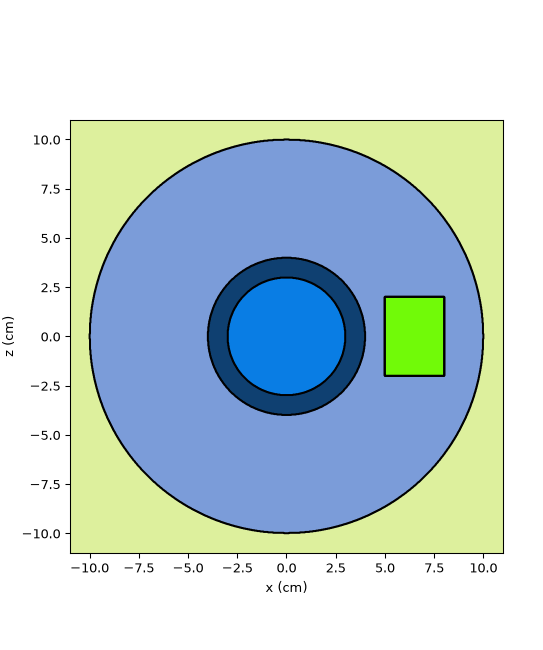